# Proyek 1: Divisive Hierarchical Clustering dengan Euclidean Distance (L2 Norm) pada BISINDO

**Deskripsi:**
Notebook ini mengimplementasikan Divisive Hierarchical Clustering (Top-Down Bipartitioning) menggunakan Bisecting 2-Means berbasis Euclidean Distance pada dataset 127 fitur gestur alfabet BISINDO.

**Formulasi Euclidean:**
$$d_{\text{Euclidean}}(x, y) = \sqrt{\sum_{i=1}^{127} (x_i - y_i)^2}$$

Pada setiap tahap, klaster dengan inersia sum-of-squares terbesar dipilih untuk dibelah menjadi 2 sub-klaster hingga terbentuk $K = 26$ klaster.

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN DAN IMPORT PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import BisectingKMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputDivisive")
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET_CLUSTERS = 26
RANDOM_STATE = 42

print(f"[INFO] Direktori: {BASE_DIR} | Target Klaster = {TARGET_CLUSTERS}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive | Target Klaster = 26


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("[INFO] Fitur berhasil distandardisasi menggunakan StandardScaler.")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur berhasil distandardisasi menggunakan StandardScaler.


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive\outputDivisive\dendrogram_euclidean.png'


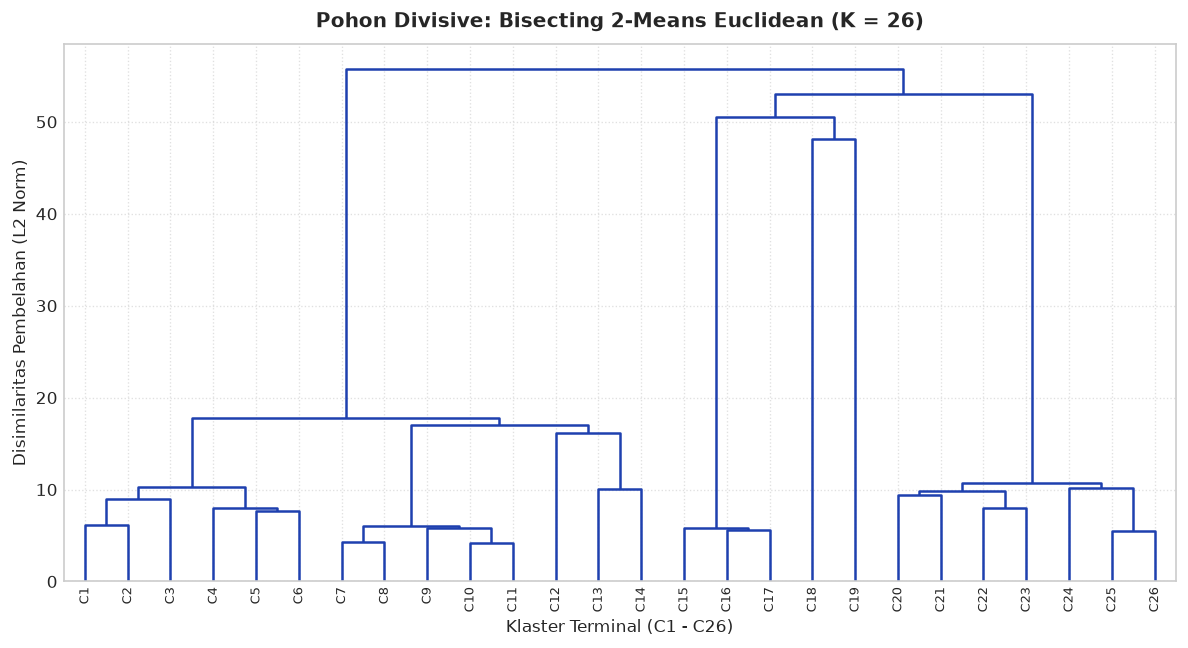

In [3]:
def build_linkage_matrix_from_tree(tree, terminal_leaves, distance_metric='euclidean'):
    leaf_to_id = {id(leaf): idx for idx, leaf in enumerate(terminal_leaves)}
    merges = []
    next_id = len(terminal_leaves)
    
    def traverse(node):
        nonlocal next_id
        if id(node) in leaf_to_id:
            center = node.center if hasattr(node, 'center') else np.zeros(127)
            return leaf_to_id[id(node)], 1, center
            
        left_id, left_count, left_center = traverse(node.left)
        right_id, right_count, right_center = traverse(node.right)
        
        if distance_metric == 'cosine':
            dot = np.dot(left_center, right_center)
            norm = np.linalg.norm(left_center) * np.linalg.norm(right_center)
            dist = max(0.001, float(1.0 - dot / (norm + 1e-9)))
        elif distance_metric == 'manhattan':
            dist = max(0.001, float(np.sum(np.abs(left_center - right_center))))
        else:
            dist = max(0.001, float(np.linalg.norm(left_center - right_center)))
            
        current_id = next_id
        next_id += 1
        total_count = left_count + right_count
        center = (left_center * left_count + right_center * right_count) / total_count
        
        merges.append([left_id, right_id, dist, total_count])
        return current_id, total_count, center

    traverse(tree)
    Z = np.array(merges, dtype=float)
    for i in range(len(Z)):
        c1, c2 = int(Z[i, 0]), int(Z[i, 1])
        h1 = Z[c1 - len(terminal_leaves), 2] if c1 >= len(terminal_leaves) else 0.0
        h2 = Z[c2 - len(terminal_leaves), 2] if c2 >= len(terminal_leaves) else 0.0
        min_h = max(h1, h2) + 0.05 * (max(h1, h2) + 0.1)
        if Z[i, 2] <= min_h:
            Z[i, 2] = min_h
    return Z

# =======================================================================
# 2. EKSEKUSI DIVISIVE BISECTING 2-MEANS (EUCLIDEAN)
# =======================================================================
t0 = time.perf_counter()
bkm = BisectingKMeans(
    n_clusters=TARGET_CLUSTERS,
    random_state=RANDOM_STATE,
    bisecting_strategy='biggest_inertia'
)
labels = bkm.fit_predict(X_scaled)
runtime_divisive = time.perf_counter() - t0

euc_leaves = list(bkm._bisecting_tree.iter_leaves())
Z = build_linkage_matrix_from_tree(bkm._bisecting_tree, euc_leaves, distance_metric='euclidean')

plt.figure(figsize=(10, 5.5))
ddata = dendrogram(
    Z,
    labels=[f"C{i+1}" for i in range(TARGET_CLUSTERS)],
    leaf_rotation=90,
    leaf_font_size=8,
    above_threshold_color='#1E40AF',
    color_threshold=0
)
plt.title(f'Pohon Divisive: Bisecting 2-Means Euclidean (K = {TARGET_CLUSTERS})', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Klaster Terminal (C1 - C26)', fontsize=10)
plt.ylabel('Disimilaritas Pembelahan (L2 Norm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

dendro_path = os.path.join(OUTPUT_DIR, "dendrogram_euclidean.png")
plt.savefig(dendro_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{dendro_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. EVALUASI METRIK KUANTITATIF EUCLIDEAN
# =======================================================================
sil = float(silhouette_score(X_scaled, labels, metric='euclidean'))
db = float(davies_bouldin_score(X_scaled, labels))
ch = float(calinski_harabasz_score(X_scaled, labels))
counts = pd.Series(labels).value_counts()

df_res = pd.DataFrame([{
    'Distance Metric': 'Euclidean Distance (L2)',
    'Divisive Strategy': 'Bisecting 2-Means (Inertia)',
    'Clusters (K)': TARGET_CLUSTERS,
    'Min Cluster Size': int(counts.min()),
    'Max Cluster Size': int(counts.max()),
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(runtime_divisive, 4)
}])

print("\n" + "="*85)
print(df_res.to_string(index=False))
print("="*85)

excel_out = os.path.join(OUTPUT_DIR, "evaluasi_divisive_euclidean.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_euclidean'] = labels

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Metrik', index=False)
    counts.to_frame(name='Jumlah_Sampel').to_excel(writer, sheet_name='Distribusi_Ukuran_Klaster')
    df_data_out.head(1000).to_excel(writer, sheet_name='Data_Klaster_Sampel', index=False)

print(f"[SAVE] Berkas evaluasi Excel disimpan ke: '{excel_out}'")


        Distance Metric           Divisive Strategy  Clusters (K)  Min Cluster Size  Max Cluster Size  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
Euclidean Distance (L2) Bisecting 2-Means (Inertia)            26                 5               817                0.1557                    1.6729                       768.85                   2.225


[SAVE] Berkas evaluasi Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive\outputDivisive\evaluasi_divisive_euclidean.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive\outputDivisive\cluster_euclidean.png'


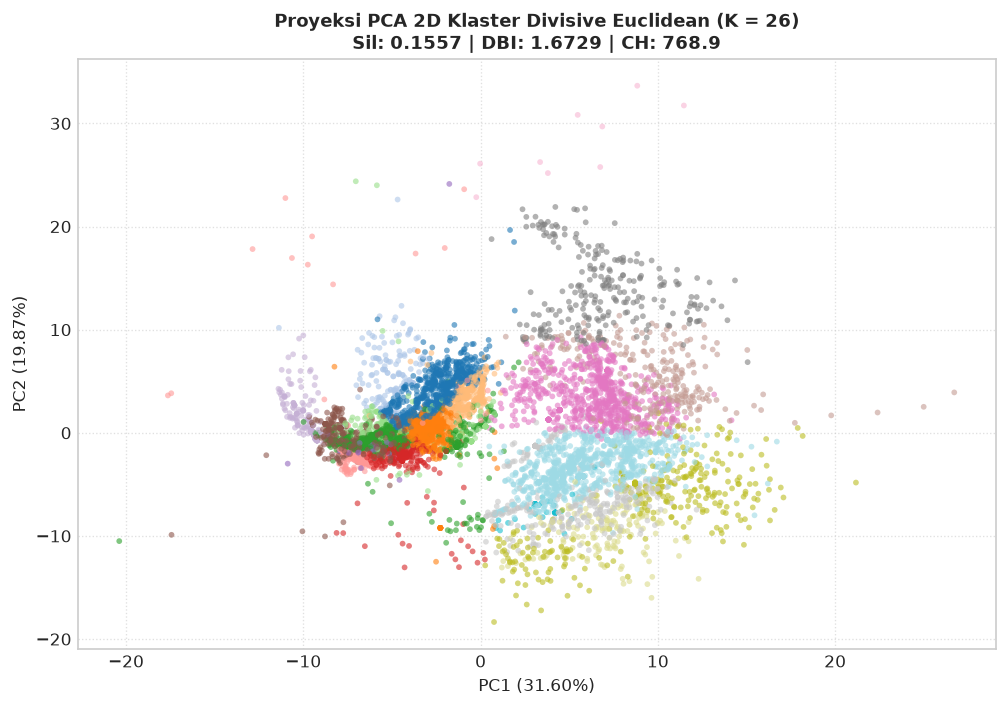

In [5]:
# =======================================================================
# 4. VISUALISASI SEBARAN KLASTER PCA 2D
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8.5, 6))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels,
    cmap='tab20',
    s=12,
    alpha=0.6,
    edgecolors='none'
)
plt.title(f'Proyeksi PCA 2D Klaster Divisive Euclidean (K = {TARGET_CLUSTERS})\nSil: {sil:.4f} | DBI: {db:.4f} | CH: {ch:.1f}', fontsize=11, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

pca_path = os.path.join(OUTPUT_DIR, "cluster_euclidean.png")
plt.savefig(pca_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{pca_path}'")
plt.show()